# The Economics of a BIST Portfolio
### Inflation, risk pricing and diversification in an emerging market

This notebook takes the portfolio from `bist_tracker.ipynb` (15 stocks, 8 sectors) and asks three economic questions:

1. **Inflation:** did Turkish equities protect purchasing power? (Fisher relation, real returns)
2. **Risk pricing:** how much of each stock's risk is market risk, and is any return left after adjusting for it? (CAPM, OLS with Newey-West standard errors)
3. **Diversification:** could the same stocks be combined better, and does that advantage survive out of sample? (Markowitz mean-variance optimisation)
4. **Dividends:** how much of the return comes from dividends, and what does that mean for comparisons with the BIST 100 price index?
5. **Monetary policy:** how do stocks, banks and the lira react to TCMB rate decisions? (event study)

Turkey is an interesting case: with high inflation and a depreciating lira, returns in TRY, in USD and in real terms can give very different answers.

> The holdings are **example positions**, not real investments. Educational project, not investment advice.

## 0. Setup

In [1]:
# Install the packages this project needs (only slow the first time)
%pip install -q -r requirements.txt


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Always use the newest version of econ.py and tracker.py, even if they
# were changed after this notebook started (no kernel restart needed)
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import econ
import tracker as tr

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

OFFLINE = False       # True = simulated data, no internet needed
MAX_WEIGHT = 0.25     # Markowitz: no single stock above 25% (a realistic constraint)

## 1. Data

yahoo: got 17 of 17 series
Prices: yahoo (AKBNK.IS, ASELS.IS, BIMAS.IS, EREGL.IS, FROTO.IS, GARAN.IS, KCHOL.IS, MGROS.IS, PGSUS.IS, SAHOL.IS, SISE.IS, TCELL.IS, THYAO.IS, TRY=X, TUPRS.IS, XU100.IS, YKBNK.IS)
Macro : TCMB via borsapy


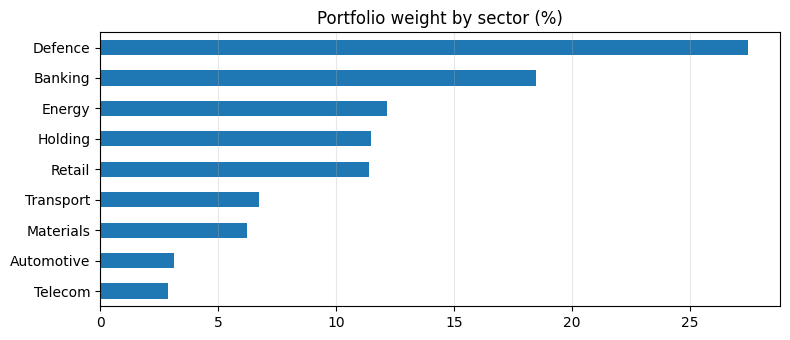

In [3]:
holdings = tr.load_holdings()
tickers = list(holdings["yahoo"]) + [tr.BENCHMARK, tr.FX_TICKER]
prices = tr.get_prices(tickers, start=holdings["buy_date"].min(), offline=OFFLINE)
holdings = tr.fill_buy_prices(holdings, prices)
macro = econ.get_macro(start=prices.index[0], offline=OFFLINE)

print("Prices:", prices.attrs["source"])
print("Macro :", macro.attrs["source"])
sectors = dict(zip(holdings["yahoo"], holdings["sector"]))
table = tr.holdings_table(holdings, prices)

fig, ax = plt.subplots(figsize=(8, 3.5))
table.groupby("sector")["weight"].sum().sort_values().mul(100).plot.barh(ax=ax)
ax.set_title("Portfolio weight by sector (%)"); ax.set_xlabel(""); ax.set_ylabel("")
ax.grid(alpha=0.3, axis="x"); plt.tight_layout(); plt.show()

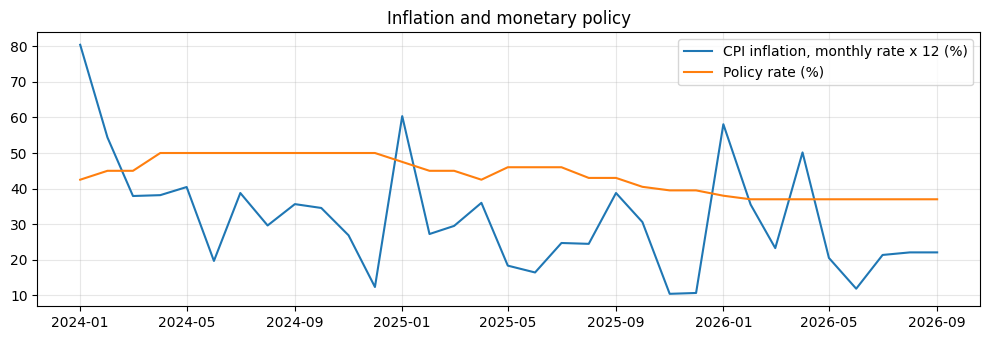

,monthly_inflation_pct,policy_rate_pct,cpi_index
Date,,,
2026-07-01,1.780,37.000,226.491
2026-08-01,1.840,37.000,230.658
2026-09-01,1.840,37.000,234.902


In [4]:
# Macro background: monthly CPI inflation and the TCMB policy rate
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(macro.index, macro["monthly_inflation_pct"] * 12, label="CPI inflation, monthly rate x 12 (%)")
ax.plot(macro.index, macro["policy_rate_pct"], label="Policy rate (%)")
ax.set_title("Inflation and monetary policy"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
macro.tail(3)

## 2. Inflation and real returns

The **Fisher relation** links nominal and real returns:

$$1 + r_{real} = \frac{1 + r_{nominal}}{1 + \pi}$$

where $\pi$ is CPI inflation. A 50% nominal gain with 45% inflation is only a 3.4% real gain.
Converting to USD is another way to look at it: it measures returns for a foreign investor.

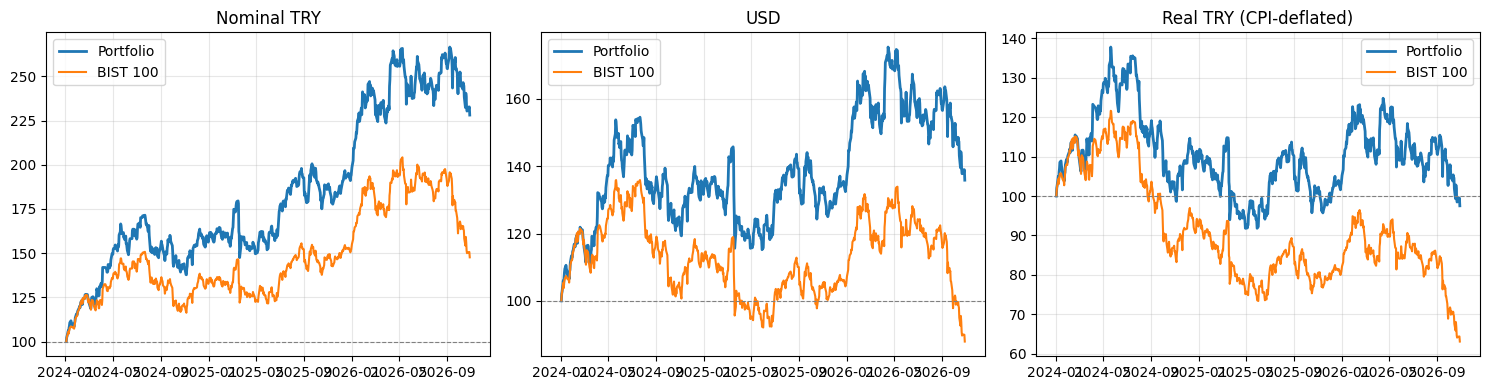

series,BIST 100,Portfolio
view,,
Nominal TRY,0.148,0.339
Real TRY (CPI-deflated),-0.150,-0.009
USD,-0.045,0.115


In [5]:
value_try = tr.portfolio_index(holdings, prices)           # time-weighted, TRY
bench_try = prices[tr.BENCHMARK].ffill().rename("BIST 100")
fx = prices[tr.FX_TICKER]

views = {
    "Nominal TRY": (value_try, bench_try),
    "USD": (tr.to_usd(value_try, fx), tr.to_usd(bench_try, fx)),
    "Real TRY (CPI-deflated)": (econ.real_index(value_try, macro), econ.real_index(bench_try, macro)),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
rows = []
for ax, (name, (p, b)) in zip(axes, views.items()):
    both = pd.concat([p, b], axis=1, join="inner").dropna()
    both = both / both.iloc[0] * 100
    ax.plot(both.index, both.iloc[:, 0], label="Portfolio", linewidth=2)
    ax.plot(both.index, both.iloc[:, 1], label="BIST 100")
    ax.axhline(100, color="grey", linestyle="--", linewidth=0.8)
    ax.set_title(name); ax.legend(); ax.grid(alpha=0.3)
    years = (both.index[-1] - both.index[0]).days / 365.25
    for col, label in zip(both.columns, ["Portfolio", "BIST 100"]):
        rows.append({"view": name, "series": label,
                     "annual return": (both[col].iloc[-1] / 100) ** (1 / years) - 1})
plt.tight_layout(); plt.show()

pd.DataFrame(rows).pivot(index="view", columns="series", values="annual return")

**How to read this:** if the real-TRY line ends below 100, the investment lost purchasing power even when the nominal line went up.
Compare the BIST 100's real return with the policy rate in section 1: in which periods did a deposit beat equities in real terms?

## 3. CAPM: how is risk priced?

For each stock we estimate the **Capital Asset Pricing Model** (Sharpe 1964; Lintner 1965) by OLS on weekly data:

$$r_{i,t} - r_{f,t} = \alpha_i + \beta_i\,(r_{m,t} - r_{f,t}) + \varepsilon_{i,t}$$

- $r_m$ = BIST 100 return, $r_f$ = TCMB policy rate converted to a weekly rate
- $\beta_i$: exposure to market (systematic) risk, which cannot be diversified away
- $\alpha_i$: return not explained by market risk. Under the CAPM, $\alpha_i = 0$
- Weekly returns reduce noise from thin trading; **Newey-West (HAC)** standard errors allow for heteroskedasticity and autocorrelation (Newey & West 1987)

In [6]:
weekly = econ.weekly_returns(prices)
stock_cols = list(holdings["yahoo"])
rf_w = econ.weekly_risk_free(macro, weekly.index)

capm = econ.capm_table(weekly[stock_cols], weekly[tr.BENCHMARK], rf_w, sectors)
capm

,sector,alpha (annual),alpha t-stat,beta,beta t-stat,R2,weeks,avg excess return (annual)
ticker,,,,,,,,
AKBNK,Banking,0.254,1.264,1.380,13.149,0.552,147,-0.023
YKBNK,Banking,0.231,1.183,1.353,11.324,0.557,147,-0.040
SAHOL,Holding,0.100,0.840,1.227,14.898,0.688,147,-0.146
GARAN,Banking,0.275,1.609,1.169,10.171,0.569,147,0.041
KCHOL,Holding,0.074,0.592,1.089,15.429,0.646,147,-0.144
BIMAS,Retail,0.233,1.642,1.012,11.065,0.464,147,0.030
SISE,Materials,-0.210,-1.991,0.995,17.884,0.625,147,-0.409
TCELL,Telecom,0.051,0.415,0.971,13.519,0.557,147,-0.143
FROTO,Automotive,-0.100,-0.613,0.916,8.989,0.482,147,-0.283


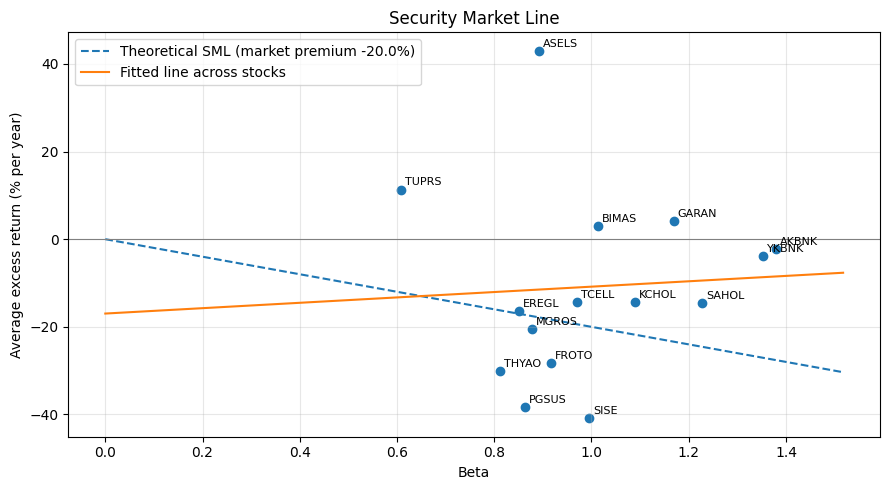

In [7]:
# Security Market Line: does higher beta come with higher average excess return?
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(capm["beta"], capm["avg excess return (annual)"] * 100)
for t, row in capm.iterrows():
    ax.annotate(t, (row["beta"], row["avg excess return (annual)"] * 100), fontsize=8,
                xytext=(3, 3), textcoords="offset points")

mkt_premium = (weekly[tr.BENCHMARK] - rf_w).mean() * econ.WEEKS_PER_YEAR
b = np.linspace(0, capm["beta"].max() * 1.1, 50)
ax.plot(b, b * mkt_premium * 100, "--", label=f"Theoretical SML (market premium {mkt_premium:.1%})")
slope, intercept = np.polyfit(capm["beta"], capm["avg excess return (annual)"], 1)
ax.plot(b, (intercept + slope * b) * 100, label="Fitted line across stocks")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Beta"); ax.set_ylabel("Average excess return (% per year)")
ax.set_title("Security Market Line"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [8]:
# The whole portfolio: one regression with the full statsmodels output
import statsmodels.api as sm

port_w = econ.weekly_returns(value_try.to_frame())["Portfolio"]
data = pd.concat([port_w - rf_w, weekly[tr.BENCHMARK] - rf_w], axis=1,
                 keys=["portfolio_excess", "market_excess"]).dropna()
fit = sm.OLS(data["portfolio_excess"], sm.add_constant(data["market_excess"])).fit(
    cov_type="HAC", cov_kwds={"maxlags": 4})
print(fit.summary().tables[1])
print(f"\nR-squared: {fit.rsquared:.2f} -> {fit.rsquared:.0%} of the portfolio's weekly variance is market risk")

                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.0031      0.001      3.272      0.001       0.001       0.005
market_excess     1.0230      0.037     27.946      0.000       0.951       1.095

R-squared: 0.92 -> 92% of the portfolio's weekly variance is market risk


**Questions to discuss**
- Which sectors have the highest betas? Banks are often high-beta in emerging markets: why might that be?
- Are any alphas statistically different from zero (|t| > 2)? Remember the **joint-hypothesis problem**: a non-zero alpha can mean mispricing *or* a wrong model.
- A flat or negative fitted line versus the theoretical SML is a well-known empirical failure of the CAPM (e.g. Fama & French 2004).

## 4. Diversification

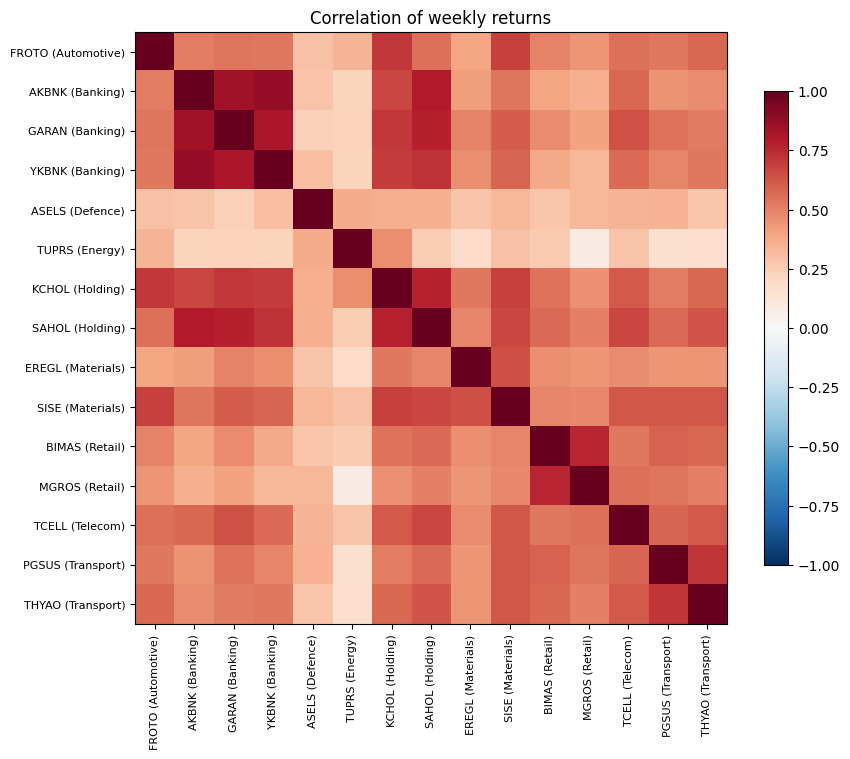

Average correlation within the same sector: 0.77
Average correlation across sectors:         0.47


In [9]:
corr = weekly[stock_cols].corr()
order = sorted(stock_cols, key=lambda t: (sectors[t], t))
corr = corr.loc[order, order]

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
labels = [f"{t.replace('.IS', '')} ({sectors[t]})" for t in order]
ax.set_xticks(range(len(order)), labels, rotation=90, fontsize=8)
ax.set_yticks(range(len(order)), labels, fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Correlation of weekly returns")
plt.tight_layout(); plt.show()

same = [corr.loc[a, b] for a in order for b in order if a < b and sectors[a] == sectors[b]]
diff = [corr.loc[a, b] for a in order for b in order if a < b and sectors[a] != sectors[b]]
print(f"Average correlation within the same sector: {np.mean(same):.2f}")
print(f"Average correlation across sectors:         {np.mean(diff):.2f}")

High correlations across *all* stocks are typical of emerging markets, where one macro factor (rates, currency, politics) moves everything together.
That limits how much diversification within the BIST alone can achieve.

## 5. Markowitz: can we combine the same stocks better?

Mean-variance optimisation (Markowitz 1952) finds the weights with the lowest risk for each level of expected return:

$$\min_w \; w'\Sigma w \quad \text{s.t.} \quad w'\mu = \mu^*, \; \sum w = 1, \; 0 \le w \le 25\%$$

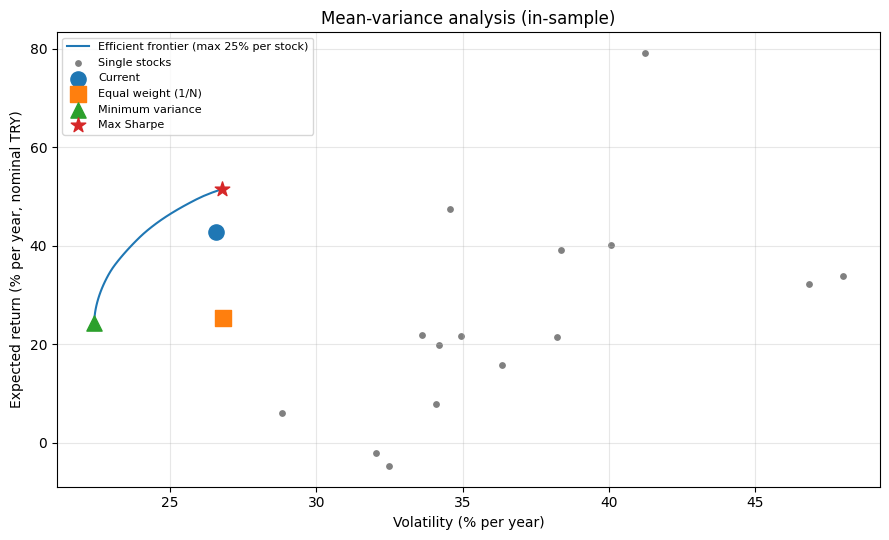

,Current,Min variance,Max Sharpe
ASELS,27.5%,7.4%,25.0%
TUPRS,12.2%,25.0%,25.0%
GARAN,9.2%,0.0%,25.0%
BIMAS,9.5%,0.0%,25.0%
THYAO,4.8%,25.0%,0.0%
PGSUS,2.0%,10.3%,0.0%
KCHOL,7.0%,0.0%,0.0%
SAHOL,4.5%,0.0%,0.0%
AKBNK,5.7%,0.0%,0.0%
YKBNK,3.5%,0.0%,0.0%


In [10]:
mu, cov = econ.annual_moments(weekly[stock_cols])
rf_annual = macro["policy_rate_pct"].iloc[-1] / 100

frontier, w_minvar = econ.efficient_frontier(mu, cov, max_weight=MAX_WEIGHT)
w_tangency = econ.max_sharpe(mu, cov, rf_annual, max_weight=MAX_WEIGHT)
w_current = table.set_index("ticker").reindex([t.replace(".IS", "") for t in stock_cols])["weight"].values
w_equal = np.repeat(1 / len(stock_cols), len(stock_cols))

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(frontier["volatility"] * 100, frontier["return"] * 100, label="Efficient frontier (max 25% per stock)")
ax.scatter(np.sqrt(np.diag(cov)) * 100, mu * 100, color="grey", s=15, label="Single stocks")
for name, w, m in [("Current", w_current, "o"), ("Equal weight (1/N)", w_equal, "s"),
                   ("Minimum variance", w_minvar, "^"), ("Max Sharpe", w_tangency, "*")]:
    r, s = econ.portfolio_stats(w, mu.values, cov.values)
    ax.scatter(s * 100, r * 100, marker=m, s=120, label=name, zorder=3)
ax.set_xlabel("Volatility (% per year)"); ax.set_ylabel("Expected return (% per year, nominal TRY)")
ax.set_title("Mean-variance analysis (in-sample)"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

weights = pd.DataFrame({"Current": w_current, "Min variance": w_minvar, "Max Sharpe": w_tangency},
                       index=[t.replace(".IS", "") for t in stock_cols])
weights[weights.max(axis=1) > 0.005].sort_values("Max Sharpe", ascending=False).style.format("{:.1%}")

### Out-of-sample test
The frontier above uses the **same data** to choose and to evaluate the weights, so it looks better than it is: means are estimated with large error.
A fair test: estimate weights on the **first half** of the sample, then measure performance on the **second half**.
DeMiguel, Garlappi & Uppal (2009) show that the naive 1/N portfolio is hard to beat out of sample.

In [11]:
half = len(weekly) // 2
train, test = weekly[stock_cols].iloc[:half], weekly[stock_cols].iloc[half:]
rf_test = rf_w.iloc[half:]

mu_tr, cov_tr = econ.annual_moments(train)
_, w_mv = econ.efficient_frontier(mu_tr, cov_tr, n_points=2, max_weight=MAX_WEIGHT)
strategies = {
    "Equal weight (1/N)": w_equal,
    "Min variance (estimated on 1st half)": w_mv,
    "Max Sharpe (estimated on 1st half)": econ.max_sharpe(mu_tr, cov_tr, rf_w.iloc[:half].mean() * 52,
                                                          max_weight=MAX_WEIGHT),
}
rows = []
for name, w in strategies.items():
    r = test.fillna(0) @ w                       # weekly returns in the 2nd half
    ex = r - rf_test
    rows.append({"strategy": name, "annual return": r.mean() * 52,
                 "annual volatility": r.std() * np.sqrt(52),
                 "Sharpe ratio": ex.mean() / ex.std() * np.sqrt(52)})
print(f"Test period: {test.index[0].date()} to {test.index[-1].date()}")
pd.DataFrame(rows).set_index("strategy")

Test period: 2025-06-06 to 2026-10-30


,annual return,annual volatility,Sharpe ratio
strategy,,,
Equal weight (1/N),0.211,0.264,-0.459
Min variance (estimated on 1st half),0.404,0.238,0.301
Max Sharpe (estimated on 1st half),0.178,0.271,-0.569


## 6. Dividends: price return vs total return

A share pays off in two ways: the **price change** and the **dividends**. Yahoo's *adjusted close* reinvests dividends, so it measures **total return**:

$$R^{total} \approx R^{price} + \text{dividend yield}$$

**Why this matters for the comparison:** the BIST 100 (`XU100`) is a **price index**: it ignores dividends.
Comparing a total-return portfolio with a price-return index flatters the portfolio by roughly the market's dividend yield. That is a benchmark bias to keep in mind when reading the tracker's "excess return".

In [12]:
price, total = econ.price_and_total_return(stock_cols + [tr.BENCHMARK], start=prices.index[0],
                                           offline=OFFLINE)
print("Source:", price.attrs["source"])

div = pd.DataFrame({"price return (annual)": econ.annualised(price[stock_cols]),
                    "total return (annual)": econ.annualised(total[stock_cols])})
div["from dividends"] = div["total return (annual)"] - div["price return (annual)"]
div.index = [t.replace(".IS", "") for t in div.index]
div.insert(0, "sector", [sectors[t + ".IS"] for t in div.index])

weights_now = table.set_index("ticker")["weight"]
port_div = (div["from dividends"] * weights_now.reindex(div.index)).sum()
bench = econ.annualised(price[[tr.BENCHMARK]]).iloc[0], econ.annualised(total[[tr.BENCHMARK]]).iloc[0]
print(f"Portfolio return from dividends (weighted): {port_div:.2%} per year")
same = abs(bench[0] - bench[1]) < 0.001
print(f"BIST 100: price {bench[0]:.2%} vs adjusted {bench[1]:.2%} per year -> "
      + ("the same: XU100 is a price index without dividends" if same else "different"))
div.sort_values("from dividends", ascending=False)

Source: Yahoo Finance
Portfolio return from dividends (weighted): 3.89% per year
BIST 100: price 14.80% vs adjusted 14.80% per year -> the same: XU100 is a price index without dividends


,sector,price return (annual),total return (annual),from dividends
TUPRS,Energy,0.381,0.529,0.148
GARAN,Banking,0.328,0.386,0.058
FROTO,Automotive,-0.034,0.024,0.058
KCHOL,Holding,0.131,0.180,0.049
AKBNK,Banking,0.225,0.267,0.042
SAHOL,Holding,0.125,0.159,0.034
TCELL,Telecom,0.171,0.200,0.029
BIMAS,Retail,0.373,0.400,0.027
MGROS,Retail,0.089,0.108,0.019
YKBNK,Banking,0.229,0.248,0.019


**Questions to discuss:** which sectors pay the most dividends? Mature companies (banks, holdings, refining) usually pay more than growth companies.
With high inflation, are dividends a meaningful part of real returns?

## 7. Event study: how does the market react to TCMB rate decisions?

Under the **efficient-market hypothesis**, prices react only to the *unexpected* part of news. We measure the reaction with an **event study** (MacKinlay 1997):

1. **Event day 0:** the first Borsa Istanbul session that could react. The decision is announced at 14:00 Istanbul time, so on a normal trading day day 0 is the decision day. If the exchange is closed (weekend, holiday) or closed early (half day before a holiday), day 0 is the next session. The dates come from the official exchange calendar (`exchange_calendars`, code `XIST`).
2. **Normal returns:** estimated on trading days −150 to −11 before each event
   - *market model* for bank stocks: $r_{i,t} = a_i + b_i r_{m,t}$
   - *constant mean* for the BIST 100 and USD/TRY
3. **Abnormal return:** $AR_t = r_t - \text{normal return}_t$; **CAR** = the sum over a window, e.g. days 0 to +1

**Hypothesis:** bank stocks react more strongly than the market to rate changes, because their funding costs and margins depend directly on the policy rate.

**Limitation:** without analysts' forecasts we cannot separate *expected* from *surprise* changes, so we can only group events by direction (hike or cut). With a small number of events, statistical power is low, so we add a **placebo test** on random dates (below).

In [13]:
# Longer price history so each event has a full estimation window before it
long_prices = tr.get_prices(stock_cols + [tr.BENCHMARK, tr.FX_TICKER], start="2023-01-01",
                            offline=OFFLINE)
daily = long_prices.pct_change()
events = econ.policy_rate_changes(start=daily.index[0] + pd.Timedelta(days=230), offline=OFFLINE)
print("Policy-rate source:", events.attrs["source"], "|", len(events), "rate changes in the sample")

# Day 0 = first Borsa Istanbul session after the 14:00 announcement (holidays and half days)
sessions = econ.align_to_sessions(events.index)
print("Calendar:", sessions.attrs["source"], "|", int(sessions["moved"].sum()),
      "decision(s) moved to the next session")
events.index = pd.DatetimeIndex(sessions["day0_session"], name="day 0 session")

banks = [t for t in stock_cols if sectors[t] == "Banking"]
bank_ret = daily[banks].mean(axis=1)                     # equal-weighted bank portfolio

ar_index = econ.event_returns(daily[tr.BENCHMARK], None, events.index, model="constant")
ar_banks = econ.event_returns(bank_ret, daily[tr.BENCHMARK], events.index, model="market")
ar_fx = econ.event_returns(daily[tr.FX_TICKER], None, events.index, model="constant")

window = (0, 1)
summary = events.loc[ar_index.index, ["change_pp", "direction", "rate_after"]].copy()
summary["CAR BIST 100 [0,+1]"] = econ.car_test(ar_index, window)[0]
summary["CAR banks vs market [0,+1]"] = econ.car_test(ar_banks, window)[0]
summary["USD/TRY abnormal change [0,+1]"] = econ.car_test(ar_fx, window)[0]
summary.style.format({"change_pp": "{:+.2f}", "rate_after": "{:.2f}",
                      "CAR BIST 100 [0,+1]": "{:+.2%}", "CAR banks vs market [0,+1]": "{:+.2%}",
                      "USD/TRY abnormal change [0,+1]": "{:+.2%}"})

yahoo: got 17 of 17 series
Policy-rate source: TCMB via borsapy | 17 rate changes in the sample
Calendar: XIST exchange calendar | 0 decision(s) moved to the next session


,change_pp,direction,rate_after,"CAR BIST 100 [0,+1]","CAR banks vs market [0,+1]","USD/TRY abnormal change [0,+1]"
2023-08-25 00:00:00,+7.50,hike,25.00,+5.47%,-9.11%,-3.53%
2023-09-22 00:00:00,+5.00,hike,30.00,+2.99%,-3.36%,+0.06%
2023-10-27 00:00:00,+5.00,hike,35.00,-0.18%,-1.49%,-0.34%
2023-11-24 00:00:00,+5.00,hike,40.00,+1.83%,+5.79%,-0.52%
2023-12-22 00:00:00,+2.50,hike,42.50,-3.10%,+0.41%,-1.55%
2024-01-26 00:00:00,+2.50,hike,45.00,+3.19%,-4.38%,+0.05%
2024-03-22 00:00:00,+5.00,hike,50.00,-1.55%,+3.61%,-1.25%
2024-12-27 00:00:00,-2.50,cut,47.50,-0.44%,-0.45%,+0.01%
2025-01-24 00:00:00,-2.50,cut,45.00,-0.98%,-0.14%,-0.24%
2025-03-07 00:00:00,-2.50,cut,42.50,-0.24%,+1.19%,+0.09%


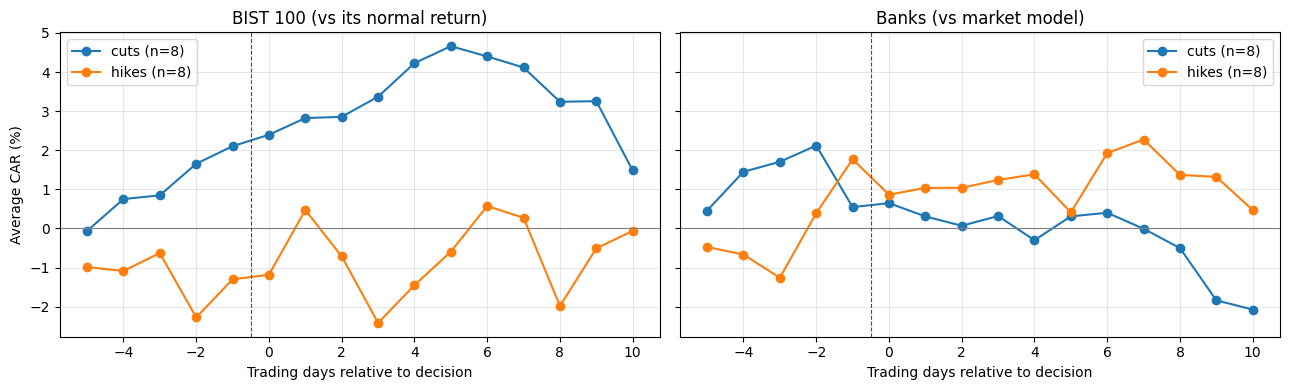

events  average CAR [0,+1]  t-stat
direction series                                             
cut       BIST 100              8               0.011   1.290
          Banks vs market       8              -0.002  -0.816
          USD/TRY               8              -0.000  -0.765
hike      BIST 100              8               0.010   0.979
          Banks vs market       8              -0.010  -0.620
          USD/TRY               8              -0.009  -2.039

In [14]:
# Average cumulative abnormal return around hikes and cuts
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (name, ar) in zip(axes, [("BIST 100 (vs its normal return)", ar_index),
                                  ("Banks (vs market model)", ar_banks)]):
    for direction, dates in summary.groupby("direction").groups.items():
        path = ar.loc[dates].cumsum(axis=1).mean() * 100
        ax.plot(path.index, path.values, marker="o", label=f"{direction}s (n={len(dates)})")
    ax.axhline(0, color="grey", linewidth=0.8); ax.axvline(-0.5, color="red", linestyle="--", linewidth=0.8)
    ax.set_title(name); ax.set_xlabel("Trading days relative to decision"); ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel("Average CAR (%)")
plt.tight_layout(); plt.show()

rows = []
for direction, dates in summary.groupby("direction").groups.items():
    for name, ar in [("BIST 100", ar_index), ("Banks vs market", ar_banks), ("USD/TRY", ar_fx)]:
        car, mean, t = econ.car_test(ar.loc[dates], window)
        rows.append({"direction": direction, "series": name, "events": len(car),
                     "average CAR [0,+1]": mean, "t-stat": t})
pd.DataFrame(rows).set_index(["direction", "series"])

**How to read this:** a CAR close to zero with a small t-statistic means the decision was largely priced in, or the sample is too small to tell.
A thesis would add **surprise measures** (decision minus analysts' consensus, or the move in short-term interest rates) and more events.

### Placebo test: are these reactions unusual?
With only 16 events, the t-test above relies on a normal distribution that may not hold. A **placebo test** asks a simpler question: *how often would random days with no rate decision give an average CAR this large?*

1. Draw 16 random trading days, at least 10 trading days away from any real decision.
2. Compute the average CAR [0,+1] on those days exactly as above.
3. Repeat 500 times. The **empirical p-value** is the share of random draws with an average CAR at least as large (in absolute value) as the real one.

If the real reaction sits inside the placebo distribution, it is not distinguishable from an ordinary day.

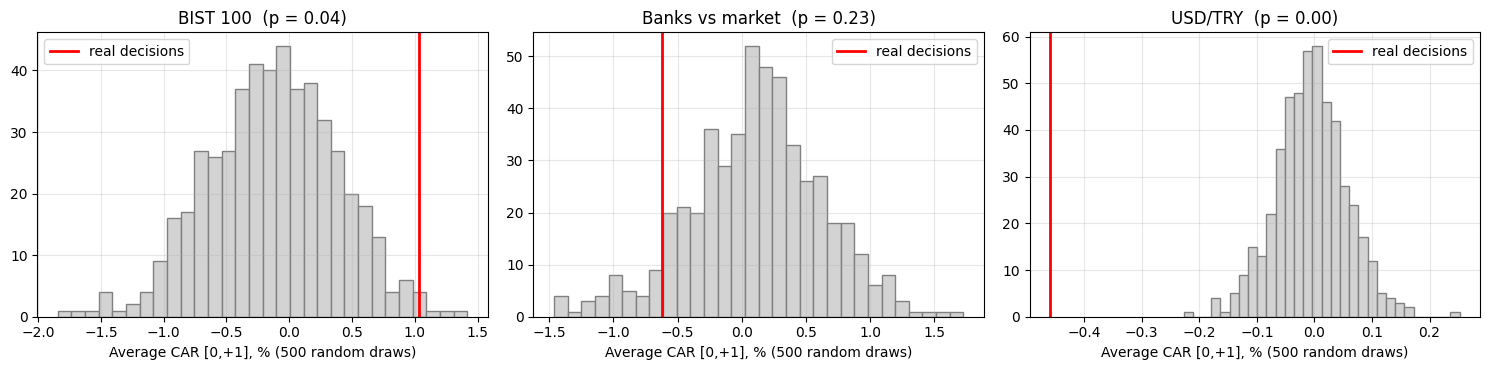

,events,real average CAR,placebo 5th pct,placebo 95th pct,empirical p-value
series,,,,,
BIST 100,16,0.010,-0.010,0.007,0.044
Banks vs market,16,-0.006,-0.008,0.009,0.230
USD/TRY,16,-0.005,-0.001,0.001,0.000


In [15]:
# Placebo distribution of the average CAR [0,+1] on random non-event days
series = [("BIST 100", daily[tr.BENCHMARK], None, "constant"),
          ("Banks vs market", bank_ret, daily[tr.BENCHMARK], "market"),
          ("USD/TRY", daily[tr.FX_TICKER], None, "constant")]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
rows = []
for ax, (name, r, mkt, model) in zip(axes, series):
    res = econ.placebo_car(r, mkt, events.index, window=window, n_draws=500, model=model)
    ax.hist(res["placebo draws"] * 100, bins=30, color="lightgrey", edgecolor="grey")
    ax.axvline(res["real mean CAR"] * 100, color="red", linewidth=2, label="real decisions")
    ax.set_title(f"{name}  (p = {res['empirical p-value']:.2f})")
    ax.set_xlabel("Average CAR [0,+1], % (500 random draws)"); ax.legend(); ax.grid(alpha=0.3)
    rows.append({"series": name, "events": res["events"], "real average CAR": res["real mean CAR"],
                 "placebo 5th pct": res["placebo draws"].quantile(0.05),
                 "placebo 95th pct": res["placebo draws"].quantile(0.95),
                 "empirical p-value": res["empirical p-value"]})
plt.tight_layout(); plt.show()
pd.DataFrame(rows).set_index("series")

**How to read this:** the grey bars show what an ordinary day looks like. A red line far in the tail (p < 0.05) means the reaction to rate decisions is unusual; a red line in the middle means it is not.
The placebo test pools hikes and cuts, so reactions of opposite sign can cancel out. Running it by direction is a natural extension.

## 8. Conclusions and extensions

**Findings (live data, January 2024 to October 2026; numbers change when you re-run):**
- **Inflation:** the BIST 100 rose about 17% a year in nominal TRY but *lost* about 13% a year in real terms (CPI-deflated) and about 2% a year in USD. Nominal returns hid a large loss of purchasing power.
- **Risk pricing:** banks and holdings have the highest betas (about 1.2–1.4), defensive names like Tüpraş the lowest (about 0.6). The market explains 20–70% of single-stock variance but 92% of the portfolio's: diversification removes most stock-specific risk.
- **Diversification:** stocks in the same sector are much more correlated (about 0.77) than stocks in different sectors (about 0.47), so spreading across sectors matters.
- **Out of sample:** in this sample the minimum-variance portfolio beat 1/N, while the max-Sharpe portfolio did worse than both. Estimates of *expected returns* are the noisy part, consistent with DeMiguel et al. (2009).
- **Dividends:** dividends added about 4% a year to the portfolio's return (over 15% a year for Tüpraş). The BIST 100 is a price index, so the tracker's excess return over it is flattered by roughly this amount.
- **Monetary policy:** across 16 rate changes since 2023 (dated to the first Borsa Istanbul session after the 14:00 announcement), the t-tests by direction are mostly not significant: with 8 events per group, power is low. The **placebo test** on 500 sets of random days is clearer. The lira's average two-day move (about −0.5%, a stronger lira) lies far outside anything seen on ordinary days (p < 0.01), driven by hikes (about −0.9%). The BIST 100 rose about 1% on decision days, more than 95% of random days (p ≈ 0.04), after both hikes and cuts, which suggests the decisions removed uncertainty. Bank stocks showed no unusual reaction relative to the market (p ≈ 0.23). Without a measure of surprise these are associations, not causal effects.

**Possible extensions**
- *Event study with surprises:* use consensus forecasts to separate expected from unexpected rate changes
- *Multi-factor models:* add a size or value factor, or the USD/TRY return as a currency factor
- *Volatility modelling:* GARCH(1,1) for time-varying risk
- *Inflation hedge test:* regress real returns on unexpected inflation

**References**
- Fama, E. & French, K. (2004). The Capital Asset Pricing Model: Theory and Evidence. *Journal of Economic Perspectives*, 18(3).
- DeMiguel, V., Garlappi, L. & Uppal, R. (2009). Optimal Versus Naive Diversification. *Review of Financial Studies*, 22(5).
- Lintner, J. (1965). The Valuation of Risk Assets. *Review of Economics and Statistics*, 47(1).
- MacKinlay, A. C. (1997). Event Studies in Economics and Finance. *Journal of Economic Literature*, 35(1).
- Markowitz, H. (1952). Portfolio Selection. *Journal of Finance*, 7(1).
- Newey, W. & West, K. (1987). A Simple, Positive Semi-Definite, Heteroskedasticity and Autocorrelation Consistent Covariance Matrix. *Econometrica*, 55(3).
- Sharpe, W. (1964). Capital Asset Prices. *Journal of Finance*, 19(3).

*Data: Yahoo Finance / borsapy (prices), TCMB via borsapy (CPI, policy rate). Educational project, not investment advice.*